# Claudius — LDI

An LDI fit to the Claudius contacts and bedding from `06a_claudius_data`, built like the
recumbent pericline (`02b`): one learnable potential α and a fixed hinge, so the velocity
∇α × *ĥ* moves material within planes normal to *ĥ* and the motion varies along it. Claudius
has no real deformation to recover, so the hinge only has to be a direction the bedding never
faces; any horizontal one will do (`HINGE`).

LDI is trained with the **energy-biased** scheme: energy-normalised cubic modes, amplitudes
started at zero and trained with plain SGD (momentum), phase and bias trained with Adam. There
is no energy penalty and no weight on one.

**How much data** (`CUTOFF`), as in `06c_claudius_surfe`: each horizon keeps that fraction of
its contacts, spaced evenly through the cloud so the kept points do not clump, and the rest are
held out to score the fit. `CUTOFF = 0.4` keeps 40%. Each setting saves under its own name,
`ldi_cut<CUTOFF>`, so it pairs with `surfe_cut<CUTOFF>`. The fault is left out, as for Surfe.

**What this notebook is.** Computation and diagnostics only; the plots are quick checks and
are *not* saved. Saved to `results/`:

- `ldi_cut<CUTOFF>.npz`, `.json`: φ, isovalues and critical points on the 06a grid, the
  younging, the distances of the fitted and held-out contacts from their level surfaces, and
  the comparison numbers;
- `fit_settings_ldi_cut<CUTOFF>.json`: the parameters;
- `restore_ldi_cut<CUTOFF>.pt`: the fitted model (`curlew.io.loadModel`);
- `meshes_ldi_cut<CUTOFF>.npz`: the horizon surfaces and the small closed level surfaces round
  any interior extremum, as plain arrays, for `06d_claudius_figures` (`MODEL = "ldi_cut<CUTOFF>"`).

## Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

import curlew
from curlew.core import CSet, HSet
from curlew.kinematics.euler import euler_velocity
from curlew.geology import restore
from curlew.io import saveModel
from curlew.priors.spectral import spectral_band, n_features_for_band

sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import diagnostics
import figstyle
import claudius_inputs

figstyle.apply()
curlew.device = "cuda" if torch.cuda.is_available() else "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 3

OUT_DIR = claudius_inputs.RESULTS_DIR
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Constraints

Each horizon is an equality, A (youngest, highest restored elevation) to D. Inequality pairs
between consecutive horizons are built too, but only weighted if `WEIGHTS` below includes
`iq_loss`.

In [2]:
SAMPLING = "seismic"      # "uniform": keep CUTOFF of each horizon, spaced evenly; "seismic": keep the contacts along 2-D seismic lines
CUTOFF = 0.4              # (uniform) fraction of each horizon kept; 1 = all
LINES = dict(n_x=5, n_y=5, half_width=20.0)   # (seismic) lines of constant x and of constant y, contacts within half_width m;
                                              # everything between the lines is held out. The bedding is kept whole either way.
IQ_SAMPLES = 64
IQ_MARGIN = 0.0           # m, minimum restored separation of consecutive horizons

data = claudius_inputs.load_processed(CUTOFF, sampling=SAMPLING, lines=LINES)
horizon_names, horizons, held_out = data["horizon_names"], data["horizons"], data["held_out"]
gp, gv = data["gp"], data["gv"]
x, y, z, box = data["x"], data["y"], data["z"], data["box"]
TAG = f"ldi_{data['tag']}"

iq_pairs = [(horizons[i], horizons[i + 1], ">", IQ_MARGIN) for i in range(len(horizons) - 1)]
C = CSet(gp=gp, gv=gv, eq=horizons, iq=(IQ_SAMPLES, iq_pairs), crs="model")   # already in the fitting frame
print(f"{data['tag']}: contacts", {n: len(h) for n, h in zip(horizon_names, horizons)},
      f"| held out {sum(len(h) for h in held_out)} | bedding {len(gp)} | grid {len(x)} x {len(y)} x {len(z)}")

seis5x5b_w20: contacts {'A': 579, 'B': 604, 'C': 611, 'D': 672} | held out 17488 | bedding 25 | grid 73 x 105 x 53


## Parameters

The Fourier basis spans a wavelength band read off the data's spectral moments (`spectral_band`: contacts give the
variance of horizon heights, bedding the variance of slopes, neighbouring bedding the variance of curvatures; the
mode count follows from the band at `MODES_PER_OCTAVE`).
`HINGE` is horizontal: material moves in sections normal to it. `EQ_SAMPLE` subsamples each
horizon's contacts every epoch (`None` uses them all).

In [7]:
MODES_PER_OCTAVE = 256
N_DIRECTIONS = 64
LSR, BAND_INFO = spectral_band(C, return_info=True)
N_FEATURES = n_features_for_band(LSR, MODES_PER_OCTAVE, N_DIRECTIONS)
print(f"band {LSR[0]:.0f}-{LSR[1]:.0f} m | M {N_FEATURES} |", BAND_INFO)
FOURIER_SEED = 42404
WEIGHTS = dict(grad_loss="1.", eq_loss="1.")
HINGE = [0.0, 1.0, 0.0]          # y (East): sections are x-z
EQ_SAMPLE = None                 # contacts per horizon per epoch; None = all

EPOCHS = 5000
N_STEPS = 0
INTEGRATOR = "shear"
LR_ADAM = 5e-3        # Adam rate for phase and bias
LR_SGD = 1e-1            # SGD rate for the amplitudes
AMP_MOMENTUM = 0.9
INIT_STD = 0.0

band 1436-6592 m | M 576 | {'m0': 23319.918946981652, 'm2': 0.0468069324334783, 'm4': 8.965891372307814e-07, 'lambda_x': 1435.6157751596722, 'lambda_0': 4434.945596656332, 'normal': [-0.04762114838677237, 0.022113154469588, 0.9986206660317666], 'normal_from_contacts': True, 'resolved': True, 'lambda_x_error': 0.1539071587404285, 'n_curvature': 308.64821316433984, 'window': 1312.4886324609145, 'contact_noise': 24.887113634513987, 'n_eff': 1.902504995597649, 'n_bedding': 25, 'n_contacts': 2466, 'n_pairs': 32, 'n_windows': 336, 'n_horizons_spanning': 4, 'profile': False, 'diameter': 6592.0632357560235, 'curvature_modes': None, 'orientations_only': False, 'strain': None}


## LDI

One learnable potential α and the fixed hinge. Integration is the Quispel–McLaren shear
splitting (`integrator="shear"`), one sequence.

**Energy-biased training.** No energy term is weighted. Instead:

- `energy_normalised=True` divides each cubic mode by the RMS of its own slope, so a mode's
  amplitude fixes its mean squared speed whatever its bias, and the bias and phase only change
  its shape;
- `INIT_STD = 0` starts every amplitude at zero, i.e. at the identity map;
- the amplitudes are trained by plain SGD (`LR_SGD`, momentum `AMP_MOMENTUM`), which, from
  zero, adds strain only in directions the data asks for; phase and bias are trained by Adam
  (`LR_ADAM`).

In [8]:
alpha = {"n_features": N_FEATURES, "n_directions": N_DIRECTIONS,
         "length_scale_range": LSR, "seed": FOURIER_SEED}
velocity = euler_velocity(3, seed=FOURIER_SEED, stream="alpha", activation="cubic",
                          alpha=alpha, hinge=HINGE, cylindrical=False, energy_normalised=True)
anchor = torch.zeros(3, dtype=curlew.dtype, device=curlew.device)      # the box centre
event = restore(
    "claudius_restore", C=C, H=HSet().zero(**WEIGHTS), velocity=velocity,
    n_steps=N_STEPS, integrator=INTEGRATOR, depth_axis=2, sigma_floor=0.0,
    init_std=INIT_STD, signed_normals=True, learning_rate=LR_ADAM, eq_sample=EQ_SAMPLE,
    optimizer={
        "amplitude": (torch.optim.SGD, dict(lr=LR_SGD, momentum=AMP_MOMENTUM, nesterov=True)),
        "shape": (torch.optim.Adam, dict(lr=LR_ADAM)),
    },
    pin=anchor,
)
for name, h in zip(reversed(horizon_names), reversed(horizons)):
    event.addIsosurface(name, seed=h)
model = curlew.GeoModel([event])
model.prefit(epochs=EPOCHS, vb=True, early_stop=None)

claudius_restore: 0/5000|

L=0.007 grad_loss=0.002 eq_loss=0.006: : 5000/5000|


{'claudius_restore': Pebble(losses={'claudius_restore': {'grad_loss': array(0.0001188, dtype=float32), 'eq_loss': array(107.319275, dtype=float32)}}, weights={'claudius_restore': {'grad_loss': 14.147775819627245, 'eq_loss': 5.2720392865777586e-05}}, optim={'claudius_restore': None}, detached=True)}

## Diagnostics

On the 06a grid:

- **interior extrema** of the field (`diagnostics.find_critical_points`);
- **younging**: the angle between the field's gradient and the bedding normals;
- **misfit**: the distance of each contact from its horizon's level surface, to first order
  `|phi - isovalue| / |grad phi|`. For the fitted contacts it is the misfit, for the held-out
  ones the prediction error, as for Surfe.

In [9]:
def field_at(x_):
    # value and gradient of the field at points
    g, v = event.field.gradient(torch.as_tensor(x_, dtype=curlew.dtype, device=curlew.device),
                                normalize=False, return_value=True)
    return v.detach().cpu().numpy().ravel(), g.detach().cpu().numpy()


grid_pts = np.stack(np.meshgrid(x, y, z, indexing="ij"), axis=-1).reshape(-1, 3)
with torch.no_grad():
    geode = model.predict(torch.as_tensor(grid_pts, dtype=curlew.dtype, device=curlew.device))
phi = np.asarray(geode.scalar).reshape(len(x), len(y), len(z))
iso_by_name = {str(k): float(v) for k, v in event.getIsovalues().items()}
isovalues = np.array([iso_by_name[n] for n in horizon_names])
critical = diagnostics.find_critical_points(event, x, y, z)

_, g_bed = field_at(gp)
cos = (g_bed * gv).sum(1) / (np.linalg.norm(g_bed, axis=1) * np.linalg.norm(gv, axis=1))
younging = np.degrees(np.arccos(np.clip(cos, -1.0, 1.0)))


def distances(sets):
    return [claudius_inputs.level_distance(*field_at(p), iso) for p, iso in zip(sets, isovalues)]


d_fit, d_held = distances(horizons), distances(held_out)
comparison = {"extrema": critical.counts, "younging_deg_median": float(np.median(younging)),
              "younging_deg_max": float(younging.max()), "fraction_reversed": float(np.mean(cos < 0)),
              "n_fit": int(sum(len(h) for h in horizons)), "isovalues": iso_by_name,
              "held_out_m_median_per_horizon": [float(np.median(d)) for d in d_held],
              **claudius_inputs.summarise_distances(d_fit, d_held)}

print(f"{TAG}: critical points {critical.counts}")
print("isovalues:", isovalues.round(3), "| in order (A highest):", bool(np.all(np.diff(isovalues) < 0)))
print(f"younging angle: median {np.median(younging):.1f}°, max {younging.max():.1f}°, reversed {np.mean(cos < 0):.2f}")
print(f"fitted contacts to their surface: median {comparison['fit_m_median']:.1f} m, 90th pct {comparison['fit_m_p90']:.1f} m")
print(f"held-out contacts: median {comparison['held_out_m_median']:.1f} m, 90th pct {comparison['held_out_m_p90']:.1f} m "
      f"(per horizon {np.round(comparison['held_out_m_median_per_horizon'], 1)})")

ldi_seis5x5b_w20: critical points {'maximum': 0, 'minimum': 0, 'saddle': 0, 'degenerate': 0}
isovalues: [ 896.104  682.103  202.381 -221.952] | in order (A highest): True
younging angle: median 0.0°, max 1.9°, reversed 0.00
fitted contacts to their surface: median 5.3 m, 90th pct 17.2 m
held-out contacts: median 14.3 m, 90th pct 52.8 m (per horizon [10.7 11.3 14.7 26.9])


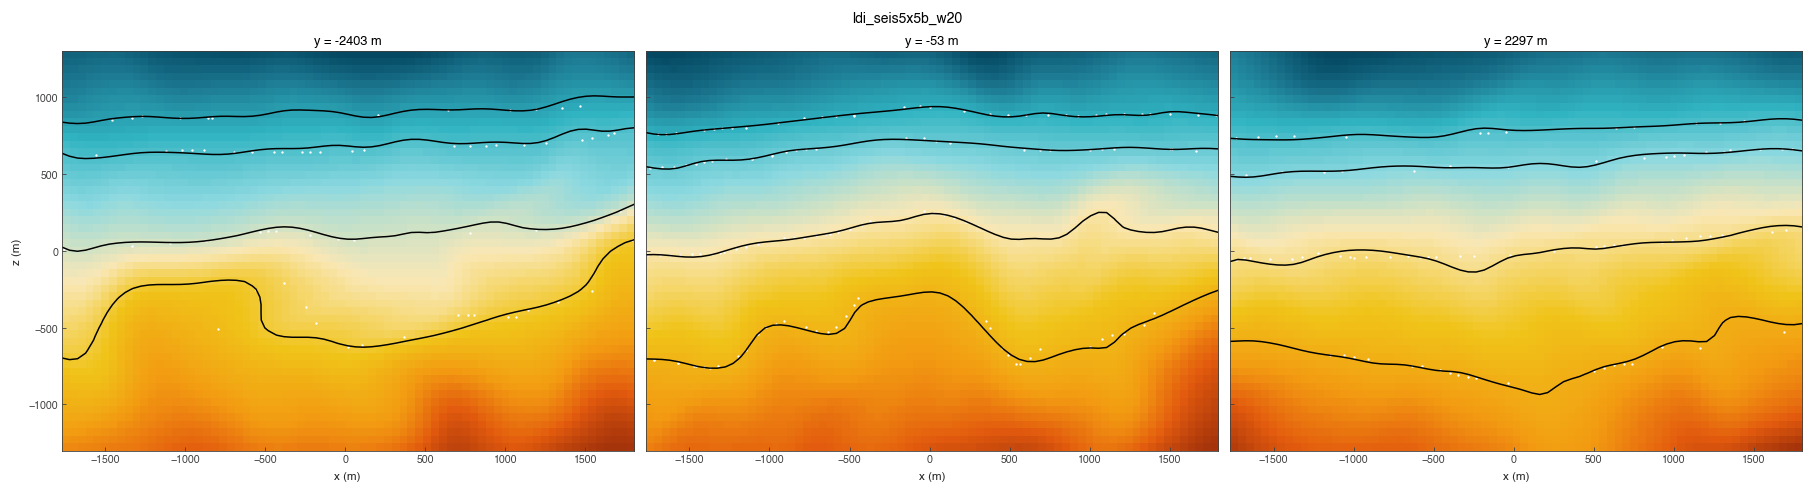

In [10]:
# Quick check (not saved): the scalar on three x-z sections, the model's contacts (black)
# and the contacts within 50 m of each section (white).
from contourpy import contour_generator

fig, axs = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True, sharey=True)
for ax, j in zip(axs, np.linspace(5, len(y) - 6, 3).astype(int)):
    sec = phi[:, j, :]
    ax.imshow(sec.T, origin="lower", extent=(x[0], x[-1], z[0], z[-1]), cmap=figstyle.ramp(), aspect="auto")
    gen = contour_generator(x=x, y=z, z=sec.T)
    for level in isovalues:
        for l in gen.lines(float(level)):
            ax.plot(*l.T, color="k", lw=0.9)
    for p in (*horizons, *held_out):
        near = np.abs(p[:, 1] - y[j]) < 10
        ax.scatter(p[near, 0], p[near, 2], s=2, color="w", linewidths=0)
    ax.set(title=f"y = {y[j]:.0f} m", xlabel="x (m)")
axs[0].set_ylabel("z (m)")
fig.suptitle(TAG)
plt.show()

## Save

In [11]:
saveModel(OUT_DIR / f"restore_{TAG}.pt", model)
np.savez_compressed(
    OUT_DIR / f"{TAG}.npz",
    phi=phi.astype(np.float32), isovalues=isovalues, younging_angle=younging,
    **{f"distance_fit_{h}": d for h, d in enumerate(d_fit)},
    **{f"distance_held_out_{h}": d for h, d in enumerate(d_held)},
    **diagnostics.pack_critical(critical),
)
parameters = {
    "sampling": SAMPLING, "cutoff": CUTOFF, "lines": LINES if SAMPLING == "seismic" else None, "iq_margin": IQ_MARGIN, "iq_samples": IQ_SAMPLES, "lsr": list(LSR), "modes_per_octave": MODES_PER_OCTAVE, "band_bedding": "25 readings + contact normals along the lines" if SAMPLING == "seismic" else "25 readings", "band_info": BAND_INFO,
    "n_features": N_FEATURES, "n_directions": N_DIRECTIONS, "fourier_seed": FOURIER_SEED, "weights": WEIGHTS,
    "hinge": HINGE, "eq_sample": EQ_SAMPLE, "epochs": EPOCHS, "n_steps": N_STEPS, "integrator": INTEGRATOR,
    "lr_adam": LR_ADAM, "lr_sgd": LR_SGD, "amp_momentum": AMP_MOMENTUM, "init_std": INIT_STD,
    "energy_normalised": True, "fault": "not used",
}
(OUT_DIR / f"fit_settings_{TAG}.json").write_text(json.dumps(parameters, indent=2, default=float))
(OUT_DIR / f"{TAG}.json").write_text(json.dumps({"comparison": comparison, "parameters": parameters},
                                                indent=1, default=float))
print(f"wrote restore_{TAG}.pt, {TAG}.npz, {TAG}.json, fit_settings_{TAG}.json to", OUT_DIR)

wrote restore_ldi_seis5x5b_w20.pt, ldi_seis5x5b_w20.npz, ldi_seis5x5b_w20.json, fit_settings_ldi_seis5x5b_w20.json to results


## Meshes for the 3-D figure

Each horizon surface is meshed over the 06a box (octree dual contouring, `GeoEvent.mesh`). For
each interior extremum, if any, the level surface just inside it is meshed at four levels, so
the figure can keep the first that closes; `SHELL_DELTA` is that level as a fraction of the
horizon spacing and `SHELL_HALF` how far (m) from the extremum a shell may reach, as in 06c.

In [12]:
MESH_DEPTH = 7                    # octree depth (2**depth cells per axis)
SHELL_DELTA = 0.08
SHELL_HALF = 300.0                # m

def mesher(level, bounds):
    v, f = event.mesh(iso=float(level), bounds=np.asarray(bounds), max_depth=MESH_DEPTH)
    return np.asarray(v), np.asarray(f)


extrema = [(p, k, float(field_at(p[None])[0][0])) for p, k in zip(critical.points, critical.kinds)
           if k in ("maximum", "minimum")]
spacing = float(np.min(np.abs(np.diff(isovalues))))
diagnostics.export_meshes(OUT_DIR / f"meshes_{TAG}.npz", mesher, isovalues, box, extrema=extrema,
                          shell_delta=SHELL_DELTA * spacing, shell_half=SHELL_HALF)
print(f"wrote meshes_{TAG}.npz: {len(isovalues)} surfaces, {len(extrema)} extrema")

wrote meshes_ldi_seis5x5b_w20.npz: 4 surfaces, 0 extrema
